# Notebook 06 — Narrative Dynamics: Timing, Crowding and Similar Fates

Notebook 05 showed that a film's *static* position in the plot network adds little to success once year, genre, language and the people involved are known. This notebook uses what the network alone ignores — **when** each story was told — and asks three sharper questions:

1. **Crowding and foresight.** Was the story already told many times in the five years *before* the film (a crowded niche)? Did later films come to resemble it more than earlier ones did (a story *ahead of its time*)? Novelty is measured against the past only, so no film is judged by what came after it.
2. **Narrative trends.** Which kinds of story rose and fell between 1990 and 2024?
3. **Similar stories, similar fates?** Do films with similar plots perform alike (network autocorrelation), and can the outcomes of a film's *earlier* plot neighbours predict its own success on films the model has not seen — better than genre can?

Return on investment (revenue ÷ budget) is added as a fifth outcome.

All results are associations, not causal effects. Inputs come from Notebooks 03–05; nothing upstream is changed. Outputs go to `outputs/tables/narrative_dynamics/`, `outputs/figures/narrative_dynamics/` and `processed/features/time_aware_plot_features.csv`.

In [1]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 1 — CONFIG
# ═══════════════════════════════════════════════════════════════════════════
CFG = {
    "project_dir": "/content/drive/MyDrive/thesis_movie_project",

    # ── time-aware plot measures ────────────────────────────────────────────
    "window_years": 5,          # look this many years back (crowding) and forward (foresight)
    "k_neighbours": 20,         # similarity to the k most similar films inside the window
    "first_year": 1990, "last_year": 2024,

    # ── outcomes ─────────────────────────────────────────────────────────────
    "min_money_for_roi": 10_000,   # budget and revenue below this are treated as unreliable for ROI

    # ── similar stories, similar fates ──────────────────────────────────────
    "moran_permutations": 499,
    "cv_folds": 5,
    "temporal_split_year": 2015,          # forward-in-time test: train on earlier films, predict 2015 onwards
    "prior_k": 20,               # plot prior = similarity-weighted outcome of the k most similar EARLIER films
    "ridge_alphas": [1, 3, 10, 30, 100, 300, 1000],
    "random_state": 42,

    # ── trends ───────────────────────────────────────────────────────────────
    "period_years": 5,           # 1990–94, 1995–99, …

    "figure_dpi": 200,
}
print("CONFIG loaded.")


CONFIG loaded.


In [2]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 2 — Imports, Drive mount, paths, style, helpers
# ═══════════════════════════════════════════════════════════════════════════
import json, re, warnings, os, shutil, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.model_selection import KFold
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.metrics import r2_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 100)
try:
    display
except NameError:
    display = print

def mount_drive():
    """Mount Google Drive in Colab. Safe to re-run."""
    try:
        from google.colab import drive
    except ImportError:
        print("Not running in Colab — using local paths.")
        return
    if os.path.ismount("/content/drive"):
        print("Google Drive already mounted.")
        return
    if os.path.isdir("/content/drive") and os.listdir("/content/drive"):
        aside = f"/content/drive_local_leftover_{time.strftime('%Y%m%d_%H%M%S')}"
        shutil.move("/content/drive", aside)
        print(f"Moved a local leftover folder (not your Drive) to {aside}.")
    drive.mount("/content/drive")
mount_drive()

PROJECT_DIR = Path(CFG["project_dir"])
if not PROJECT_DIR.exists():
    raise FileNotFoundError(f"Project folder not found: {PROJECT_DIR}. Check that Google Drive is mounted "
                            "(left sidebar → Files → drive/MyDrive) and that CFG['project_dir'] is right.")
NETWORK_DIR  = PROJECT_DIR / "processed" / "network"
FEATURES_DIR = PROJECT_DIR / "processed" / "features"
TABLES_DIR   = PROJECT_DIR / "outputs" / "tables"
D_TABLES     = TABLES_DIR / "narrative_dynamics"
D_FIGS       = PROJECT_DIR / "outputs" / "figures" / "narrative_dynamics"
for d in [D_TABLES, D_FIGS]:
    d.mkdir(parents=True, exist_ok=True)

MODEL_TABLE = FEATURES_DIR / "modeling_table_success_star_power.csv"
EDGES_FILE  = NETWORK_DIR / "semantic_network_edges_mutual_knn.csv"
MANIFEST    = NETWORK_DIR / "network_manifest.json"
LABELED     = TABLES_DIR / "community_manual_labeling_template_labeled.csv"
FEATURES_OUT = FEATURES_DIR / "time_aware_plot_features.csv"

INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 24,
    "axes.labelsize": 10, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "font.family": "DejaVu Sans", "lines.linewidth": 2, "legend.frameon": False,
})

def subtitle(ax, text):
    ax.annotate(text, xy=(0, 1), xycoords="axes fraction", xytext=(0, 6), textcoords="offset points",
                fontsize=9.5, color=INK_2, va="bottom", ha="left")

def fig_header(fig, title, sub, band_in=0.85):
    """Lay out panels first, then put title and subtitle in a fixed-height band (inches) above them."""
    h = fig.get_figheight()
    fig.tight_layout()
    fig.subplots_adjust(top=1 - band_in / h)          # enforce the band even if tight_layout gives up
    fig.text(0.01, 1 - 0.05 / h, title, fontsize=13, fontweight="bold", color=INK, va="top")
    fig.text(0.01, 1 - 0.37 / h, sub, fontsize=9.5, color=INK_2, va="top")

def save(fig, table, name):
    fig.savefig(D_FIGS / f"{name}.png", dpi=CFG["figure_dpi"], bbox_inches="tight")
    table.to_csv(D_TABLES / f"{name}.csv", index=False)
    plt.show()
    print(f"  ✓ figures/narrative_dynamics/{name}.png + tables/narrative_dynamics/{name}.csv")

def save_tab(df, name):
    df.to_csv(D_TABLES / name, index=False)
    print(f"  ✓ tables/narrative_dynamics/{name}")

def z(s):
    s = pd.to_numeric(s, errors="coerce")
    return (s - s.mean()) / s.std()

print("PROJECT_DIR:", PROJECT_DIR)


Mounted at /content/drive
PROJECT_DIR: /content/drive/MyDrive/thesis_movie_project


In [3]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 3 — Load the modelling table (Notebook 05), embeddings (Notebook 03) and edges
# ═══════════════════════════════════════════════════════════════════════════
missing = [p.name for p in [MODEL_TABLE, EDGES_FILE, LABELED] if not p.exists()]
if missing:
    raise FileNotFoundError(f"Missing {missing}. Run Notebooks 03, 04 and 05 v2 first.")
df = pd.read_csv(MODEL_TABLE, low_memory=False)
edges = pd.read_csv(EDGES_FILE, usecols=["source_node_id", "target_node_id", "cosine_similarity"])
labels = pd.read_csv(LABELED)
manifest = json.loads(MANIFEST.read_text()) if MANIFEST.exists() else {}
tag = "_names_masked" if manifest.get("config", {}).get("mask_person_names", False) else ""
emb_file = FEATURES_DIR / f"sbert_minilm_embeddings{tag}.npy"
idx_file = FEATURES_DIR / f"sbert_minilm_embedding_index{tag}.csv"
if not idx_file.exists():
    idx_file = FEATURES_DIR / "sbert_minilm_embedding_index.csv"
if not emb_file.exists():
    raise FileNotFoundError(f"{emb_file.name} not found — run Notebook 03 v2.")
E = np.load(emb_file).astype(np.float32)
E /= np.linalg.norm(E, axis=1, keepdims=True)
emb_index = pd.read_csv(idx_file)
if "release_year" not in emb_index or len(emb_index) != len(E):
    raise ValueError("Embedding index does not match the embedding matrix — re-run Notebook 03 v2.")
emb_index["row"] = np.arange(len(E))
print(f"modelling table {df.shape} · embeddings {E.shape} ({emb_file.name}) · edges {len(edges):,}")
missing_emb = (~df["tmdb_id"].isin(emb_index["tmdb_id"])).sum()
print(f"Network films without an embedding: {missing_emb} (expected 0)")

MAJOR = labels["community_id"].tolist()
lab = labels.set_index("community_id")
short_col = "short_label" if "short_label" in lab and lab["short_label"].notna().any() else "suggested_label_manual"
SHORT = {c: f"C{c} · {lab.loc[c, short_col]}" for c in MAJOR}

# return on investment (only where both numbers are plausible)
mm = CFG["min_money_for_roi"]
ok = (df["revenue_clean"] >= mm) & (df["budget_clean"] >= mm)
df["log_roi"] = np.where(ok, np.log(df["revenue_clean"].where(ok) / df["budget_clean"].where(ok)), np.nan)
print(f"ROI available for {int(ok.sum()):,} films (median revenue/budget = {np.exp(df['log_roi'].median()):.2f}×)")


modelling table (19084, 89) · embeddings (19919, 384) (sbert_minilm_embeddings_names_masked.npy) · edges 70,252
Network films without an embedding: 0 (expected 0)
ROI available for 4,910 films (median revenue/budget = 1.58×)


## 1. Time-aware plot measures

For every film released in year *y* (all 19,919 network-corpus films are used as the reference pool):

| Measure | Definition | Reading |
|---|---|---|
| **crowding** | mean cosine similarity to its 20 most similar films released in *y−5 … y−1* | high = the story had been told many times just before |
| **echo** | the same, for films released in *y+1 … y+5* | high = similar stories followed |
| **foresight** | echo − crowding | high = later films resembled it more than earlier ones did: *ahead of its time* |
| **competition** | the same, for other films released in year *y* | high = many similar stories at the same moment |

The number of films per year grows over time, and more films means closer nearest neighbours, so every measure is **standardised within release year** (a z-score among films of the same year). Crowding needs a full past window (from 1995), echo and foresight a full future window (until 2019).

In [4]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 4 — Crowding, echo, foresight and competition (one matrix product per year)
# ═══════════════════════════════════════════════════════════════════════════
W, K = CFG["window_years"], CFG["k_neighbours"]
years = emb_index["release_year"].values
rows_by_year = {y: np.where(years == y)[0] for y in np.unique(years)}

def topk_mean(Q_rows, P_rows, k, same=False):
    if len(P_rows) == 0:
        return np.full(len(Q_rows), np.nan)
    S = E[Q_rows] @ E[P_rows].T
    if same:
        np.fill_diagonal(S, -np.inf)
    kk = min(k, S.shape[1] - (1 if same else 0))
    if kk <= 0:
        return np.full(len(Q_rows), np.nan)
    return np.partition(S, -kk, axis=1)[:, -kk:].mean(axis=1)

t0 = time.time()
meas = {m: np.full(len(E), np.nan) for m in ["crowding", "echo", "competition"]}
for y, q in rows_by_year.items():
    past = np.where((years >= y - W) & (years <= y - 1))[0]
    future = np.where((years >= y + 1) & (years <= y + W))[0]
    if y - W >= CFG["first_year"]:
        meas["crowding"][q] = topk_mean(q, past, K)
    if y + W <= CFG["last_year"]:
        meas["echo"][q] = topk_mean(q, future, K)
    meas["competition"][q] = topk_mean(q, q, K, same=True)
tm = emb_index[["tmdb_id", "release_year"]].copy()
for m, v in meas.items():
    tm[f"{m}_raw"] = v
tm["foresight_raw"] = tm["echo_raw"] - tm["crowding_raw"]
for m in ["crowding", "echo", "foresight", "competition"]:
    g = tm.groupby("release_year")[f"{m}_raw"]
    tm[f"{m}_z"] = (tm[f"{m}_raw"] - g.transform("mean")) / g.transform("std")
print(f"Computed in {time.time() - t0:.0f}s for {len(tm):,} films.")
display(tm[[c for c in tm if c.endswith("_raw")]].describe().round(3))

df = df.drop(columns=[c for c in tm.columns if c in df.columns and c not in ("tmdb_id", "release_year")]).merge(
    tm.drop(columns="release_year"), on="tmdb_id", how="left")
df[["tmdb_id", "title", "release_year", "community_id"] + [c for c in tm.columns if c.endswith(("_raw", "_z"))]] \
  .to_csv(FEATURES_OUT, index=False)
print(f"  ✓ processed/features/{FEATURES_OUT.name}")
print("Correlation between measures (Spearman):")
display(df[["crowding_z", "echo_z", "foresight_z", "competition_z", "novelty"]].corr(method="spearman").round(2))


Computed in 3s for 19,919 films.


,crowding_raw,echo_raw,competition_raw,foresight_raw
count,18715.000,16115.000,19919.000,14911.000
mean,0.469,0.472,0.415,0.007
std,0.060,0.060,0.061,0.017
min,0.225,0.215,0.149,-0.082
25%,0.428,0.431,0.374,-0.004
50%,0.470,0.473,0.416,0.006
75%,0.511,0.514,0.458,0.017
max,0.654,0.658,0.611,0.162


  ✓ processed/features/time_aware_plot_features.csv
Correlation between measures (Spearman):


,crowding_z,echo_z,foresight_z,competition_z,novelty
crowding_z,1.00,0.96,-0.16,0.95,-0.94
echo_z,0.96,1.00,0.09,0.94,-0.95
foresight_z,-0.16,0.09,1.00,-0.06,0.01
competition_z,0.95,0.94,-0.06,1.00,-0.89
novelty,-0.94,-0.95,0.01,-0.89,1.00


In [5]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 5 — Sanity check: which well-known films look 'ahead of their time' or 'crowded'?
# ═══════════════════════════════════════════════════════════════════════════
known = df[df["vote_count"] >= 1000].dropna(subset=["foresight_z"])
cols = ["title", "release_year", "suggested_label_manual", "crowding_z", "echo_z", "foresight_z"]
ahead = known.sort_values("foresight_z", ascending=False)[cols].head(15)
crowded = known.dropna(subset=["crowding_z"]).sort_values("crowding_z", ascending=False)[cols].head(15)
print("Highest foresight (later films resembled them more than earlier ones did):"); display(ahead.round(2))
print("Most crowded at release (the story had been told many times just before):"); display(crowded.round(2))
save_tab(pd.concat([ahead.assign(list="ahead_of_time"), crowded.assign(list="crowded")]), "examples_foresight_crowding.csv")


Highest foresight (later films resembled them more than earlier ones did):


,title,release_year,suggested_label_manual,crowding_z,echo_z,foresight_z
10993,Apollo 18,2011,"Science fiction, space, robots and superhero worlds",-3.29,-2.07,5.00
5549,No Reservations,2007,Minor community (pooled),-1.24,-0.05,4.22
8676,The Last Exorcism,2010,"Supernatural horror: hauntings, demons and possession",0.42,1.34,3.79
16095,Justice League vs. Teen Titans,2016,"Science fiction, space, robots and superhero worlds",-1.36,-0.37,3.72
3814,Underworld,2003,Vampires and werewolves,-0.54,0.53,3.69
5510,Knocked Up,2007,"Family secrets, siblings and domestic threat",0.11,1.11,3.61
1562,Mars Attacks!,1996,"Science fiction, space, robots and superhero worlds",-1.93,-1.15,3.52
11531,The Hunger Games: Catching Fire,2013,"Fairy tales, royalty and mythic fantasy",-2.07,-1.18,3.47
6248,The Switch,2010,"Family secrets, siblings and domestic threat",0.19,1.01,3.41
10139,War Horse,2011,"Sports teams, coaches and competition",-0.37,0.46,3.29


Most crowded at release (the story had been told many times just before):


,title,release_year,suggested_label_manual,crowding_z,echo_z,foresight_z
9169,Remember Me,2010,"Romance, marriage and relationship drama-comedy",2.78,2.66,-0.54
11222,Gone,2012,"Family secrets, siblings and domestic threat",2.73,2.73,-0.11
2930,Sweet November,2001,"Romance, marriage and relationship drama-comedy",2.67,2.56,-0.80
3599,Jersey Girl,2004,"Music, bands and performers' careers",2.55,2.04,-1.70
17003,Ghostland,2018,"Family secrets, siblings and domestic threat",2.47,2.68,0.80
10217,House at the End of the Street,2012,"Family secrets, siblings and domestic threat",2.40,2.31,-0.44
17243,Haunt,2019,"Supernatural horror: hauntings, demons and possession",2.38,1.95,-1.59
18020,Hereditary,2018,"Family secrets, siblings and domestic threat",2.31,2.52,0.81
2869,The Family Man,2000,"Romance, marriage and relationship drama-comedy",2.31,2.18,-0.76
13082,Crimson Peak,2015,"Romance, marriage and relationship drama-comedy",2.28,2.42,0.45


  ✓ tables/narrative_dynamics/examples_foresight_crowding.csv


## 2. Narrative trends, 1990–2024

Each community's share of the films released in each five-year period, compared with its overall share (**lift**; 1 = its usual share). Rows are ordered by the year in which each community peaks, so rising and fading stories form a diagonal.

,community_id,label,share_pct_overall,trend_pp_per_decade,ci_low,ci_high,p_value,peak_year,relative_change_per_decade_pct
0,0,"Crime, policing and the criminal underworld",9.554,-2.065,-2.740,-1.390,0.000,1991,-21.613
1,1,"Romance, marriage and relationship drama-comedy",7.643,-0.489,-0.968,-0.010,0.045,1997,-6.403
18,18,"Espionage, secret agents, terrorism and hackers",1.613,-0.421,-0.751,-0.092,0.012,1994,-26.118
13,13,"Film-making, acting and show business",2.872,-0.343,-0.667,-0.019,0.038,1996,-11.934
22,22,Boxing and martial-arts fighters,1.197,-0.338,-0.610,-0.066,0.015,1993,-28.232
6,6,"Fairy tales, royalty and mythic fantasy",4.586,-0.322,-0.733,0.089,0.125,1993,-7.018
4,4,"Science fiction, space, robots and superhero worlds",6.295,-0.283,-0.852,0.286,0.329,1995,-4.495
11,11,Animals and pets: family animal adventures,3.355,-0.241,-0.503,0.021,0.071,1998,-7.190


,community_id,label,share_pct_overall,trend_pp_per_decade,ci_low,ci_high,p_value,peak_year,relative_change_per_decade_pct
25,25,"Twins, sisters and family identity (mixed)",1.040,0.204,0.058,0.349,0.006,2019,19.576
14,14,"The sea: ships, sharks, pirates and island survival",2.512,0.237,-0.015,0.488,0.065,2024,9.420
8,8,"Japanese and Korean cinema: samurai, yakuza, school life and anime",3.929,0.291,-0.058,0.641,0.102,2013,7.419
10,10,Latin American and Spanish-language drama,3.642,0.365,0.070,0.659,0.015,2021,10.013
3,3,"War, historical conflict and military action",7.003,0.404,-0.065,0.874,0.092,2019,5.773
5,5,"Supernatural horror: hauntings, demons and possession",6.064,0.678,0.205,1.151,0.005,2015,11.185
7,7,French relationship and family drama-comedy,4.030,0.836,0.584,1.087,0.000,2024,20.738
2,2,"Family secrets, siblings and domestic threat",7.565,1.043,0.562,1.525,0.000,2021,13.792


  ✓ tables/narrative_dynamics/community_trends.csv


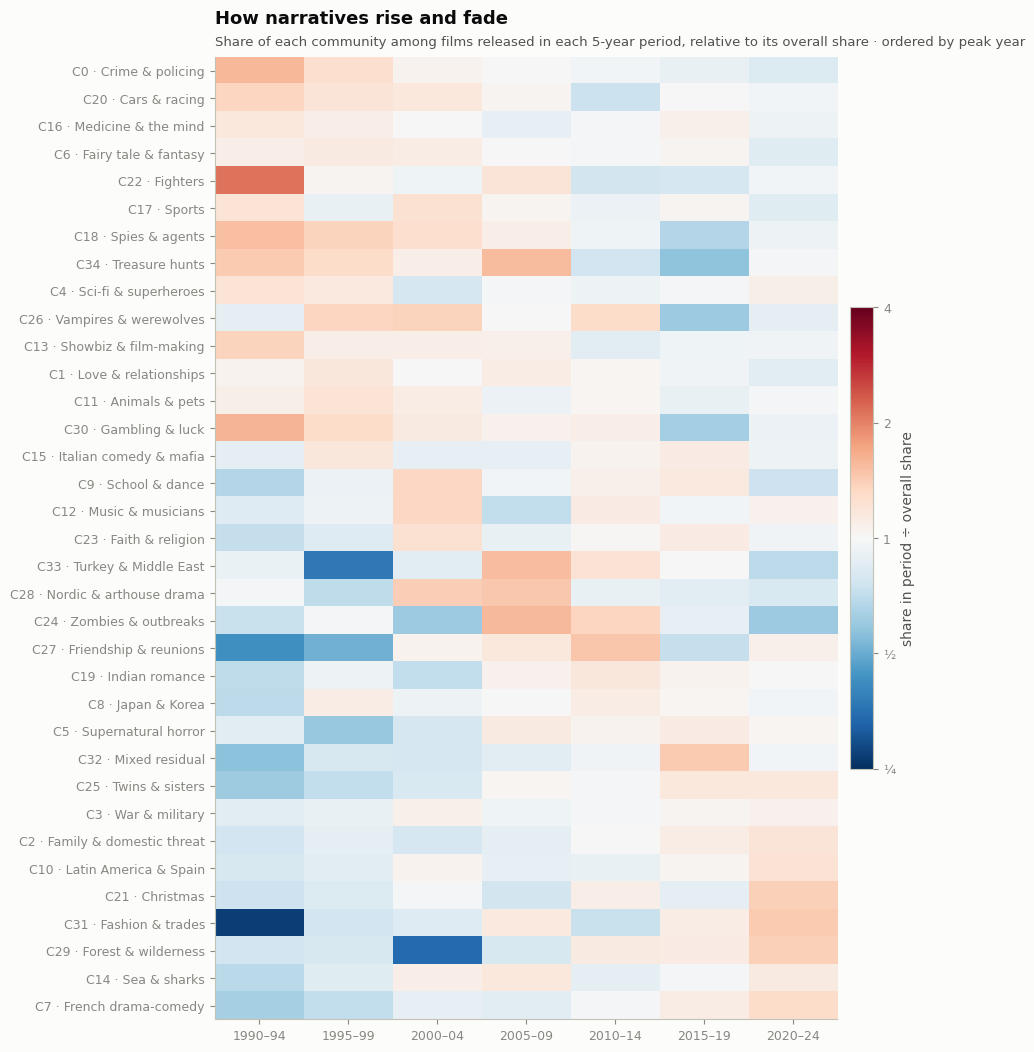

  ✓ figures/narrative_dynamics/fig_01_narrative_trends.png + tables/narrative_dynamics/fig_01_narrative_trends.csv


In [6]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 6 — Community shares over time + rising/fading trend table
# ═══════════════════════════════════════════════════════════════════════════
P = CFG["period_years"]
df["period"] = (df["release_year"] - CFG["first_year"]) // P * P + CFG["first_year"]
m = df[df["community_id"].isin(MAJOR)]
share = pd.crosstab(m["community_id"], m["period"], normalize="columns")
overall = m["community_id"].value_counts(normalize=True)
lift = share.div(overall, axis=0)
yearly = pd.crosstab(m["community_id"], m["release_year"], normalize="columns")
peak = (yearly.T.rolling(5, center=True, min_periods=3).mean()).idxmax()
order = peak.sort_values().index.tolist()

# trend: slope of yearly share (percentage points per decade) with a 95% CI
trend_rows = []
for c in MAJOR:
    s = yearly.loc[c]
    r = smf.ols("s ~ year", data=pd.DataFrame({"s": s.values * 100, "year": s.index.values})).fit(cov_type="HC3")
    trend_rows.append({"community_id": c, "label": lab.loc[c, "suggested_label_manual"],
                       "share_pct_overall": overall[c] * 100, "trend_pp_per_decade": r.params["year"] * 10,
                       "ci_low": r.conf_int().loc["year", 0] * 10, "ci_high": r.conf_int().loc["year", 1] * 10,
                       "p_value": r.pvalues["year"], "peak_year": int(peak[c])})
trend = pd.DataFrame(trend_rows).sort_values("trend_pp_per_decade")
trend["relative_change_per_decade_pct"] = trend["trend_pp_per_decade"] / trend["share_pct_overall"] * 100
display(trend.round(3).head(8)); display(trend.round(3).tail(8))
save_tab(trend.round(4), "community_trends.csv")

L = np.log2(lift.loc[order].clip(lower=0.25, upper=4))
fig, ax = plt.subplots(figsize=(8.5, 0.3 * len(order) + 2))
im = ax.imshow(L.values, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(L.shape[1]), [f"{p}–{str(p + P - 1)[2:]}" for p in L.columns], rotation=0)
ax.set_yticks(range(len(order)), [SHORT[c] for c in order])
ax.grid(False)
cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
cb.set_ticks([-2, -1, 0, 1, 2]); cb.set_ticklabels(["¼", "½", "1", "2", "4"])
cb.set_label("share in period ÷ overall share")
ax.set_title("How narratives rise and fade")
subtitle(ax, f"Share of each community among films released in each {P}-year period, relative to its overall share · ordered by peak year")
save(fig, L.reset_index().rename(columns={"community_id": "community_id"}), "fig_01_narrative_trends")


## 3. Does it pay to arrive early — or to tell a story that becomes the future?

First a picture: average outcome by decile of crowding and of foresight (raw, before controls). Then the regression, with the same controls as Notebook 05 (year fixed effects, genre, runtime, English, cast and director star power) **plus the 35 communities**, so the comparison is *between films of the same kind of story*.

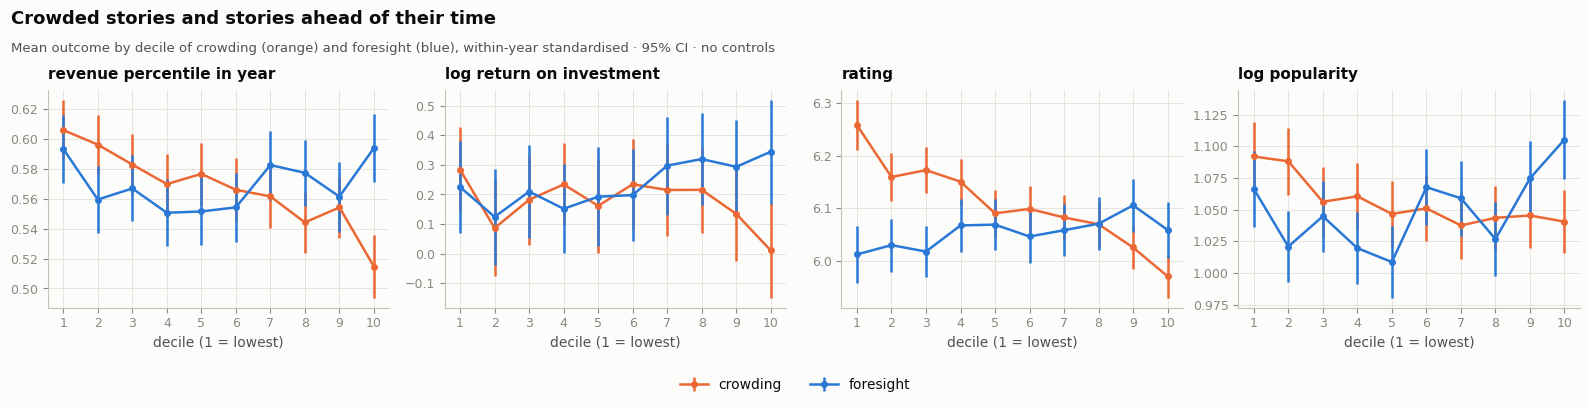

  ✓ figures/narrative_dynamics/fig_02_binned_crowding_foresight.png + tables/narrative_dynamics/fig_02_binned_crowding_foresight.csv


In [7]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 7 — Binned picture: outcomes across deciles of crowding and foresight
# ═══════════════════════════════════════════════════════════════════════════
OUT = {"revenue_percentile_year": "revenue percentile in year", "log_roi": "log return on investment",
       "vote_average": "rating", "log_popularity": "log popularity"}
fig, axes = plt.subplots(1, len(OUT), figsize=(4 * len(OUT), 3.6))
bins_tab = []
for ax, (y, name) in zip(axes, OUT.items()):
    for meas_, color in [("crowding_z", SERIES[1]), ("foresight_z", SERIES[0])]:
        d = df.dropna(subset=[y, meas_])
        d = d.assign(decile=pd.qcut(d[meas_], 10, labels=False, duplicates="drop") + 1)
        g = d.groupby("decile")[y].agg(["mean", "sem", "size"]).reset_index()
        ax.errorbar(g["decile"], g["mean"], yerr=1.96 * g["sem"], color=color, marker="o", markersize=4,
                    capsize=0, linewidth=1.8, label=meas_.replace("_z", ""))
        bins_tab.append(g.assign(outcome=y, measure=meas_))
    ax.set_title(name, fontsize=11, pad=8)
    ax.set_xlabel("decile (1 = lowest)")
    ax.set_xticks(range(1, 11))
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2)
fig_header(fig, "Crowded stories and stories ahead of their time",
           "Mean outcome by decile of crowding (orange) and foresight (blue), within-year standardised · 95% CI · no controls")
save(fig, pd.concat(bins_tab, ignore_index=True), "fig_02_binned_crowding_foresight")


In [8]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 8 — Regressions: time-aware measures on top of all Notebook 05 controls
# ═══════════════════════════════════════════════════════════════════════════
gc = df["primary_genre_model"].fillna("Other")
df["primary_genre_model"] = gc
BASE = ("C(release_year) + C(primary_genre_model) + z_runtime + is_english + z_star_index + z_director_index + has_star "
        "+ C(community_group)")
SPECS = {
    "T1_crowding": "crowding_z + I(crowding_z**2)",
    "T2_crowding_foresight": "crowding_z + I(crowding_z**2) + foresight_z",
    "T3_plus_competition": "crowding_z + I(crowding_z**2) + foresight_z + competition_z",
}
need = ["release_year", "primary_genre_model", "z_runtime", "is_english", "z_star_index", "z_director_index",
        "has_star", "community_group"]

def fit(formula, data):
    return smf.ols(formula, data=data).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(data["community_group"])[0]})

res_rows, fits = [], {}
for y in OUT:
    for name, terms in SPECS.items():
        d = df.dropna(subset=[y] + need + [v for v in ["crowding_z", "foresight_z", "competition_z"] if v in terms])
        r = fit(f"{y} ~ {BASE} + {terms}", d)
        base_r2 = fit(f"{y} ~ {BASE}", d).rsquared
        fits[(y, name)] = r
        ci = r.conf_int()
        for t in r.params.index:
            if any(k in t for k in ["crowding", "foresight", "competition"]):
                res_rows.append({"outcome": y, "model": name, "term": t, "coef": r.params[t], "ci_low": ci.loc[t, 0],
                                 "ci_high": ci.loc[t, 1], "p_value": r.pvalues[t], "n_obs": int(r.nobs),
                                 "r2": r.rsquared, "r2_gain_over_base": r.rsquared - base_r2})
timing = pd.DataFrame(res_rows)
display(timing[timing["model"] == "T3_plus_competition"].round(4))
save_tab(timing.round(5), "timing_regressions.csv")

# heterogeneity: does crowding hurt more for some films?
het = []
for y in ["revenue_percentile_year", "vote_average"]:
    d = df.dropna(subset=[y, "crowding_z"] + need)
    r = fit(f"{y} ~ {BASE} + crowding_z*is_english + crowding_z*has_star", d)
    for t in ["crowding_z", "crowding_z:is_english", "crowding_z:has_star"]:
        het.append({"outcome": y, "term": t, "coef": r.params[t], "p_value": r.pvalues[t], "n_obs": int(r.nobs)})
het = pd.DataFrame(het)
display(het.round(4))
save_tab(het.round(5), "timing_heterogeneity.csv")


,outcome,model,term,coef,ci_low,ci_high,p_value,n_obs,r2,r2_gain_over_base
5,revenue_percentile_year,T3_plus_competition,crowding_z,0.0280,-0.0014,0.0574,0.0624,5689,0.3318,0.0029
6,revenue_percentile_year,T3_plus_competition,I(crowding_z ** 2),-0.0044,-0.0090,0.0002,0.0589,5689,0.3318,0.0029
7,revenue_percentile_year,T3_plus_competition,foresight_z,0.0076,0.0017,0.0135,0.0119,5689,0.3318,0.0029
8,revenue_percentile_year,T3_plus_competition,competition_z,-0.0389,-0.0685,-0.0093,0.0101,5689,0.3318,0.0029
14,log_roi,T3_plus_competition,crowding_z,0.0856,-0.0999,0.2711,0.3657,3876,0.0813,0.0029
15,log_roi,T3_plus_competition,I(crowding_z ** 2),-0.0356,-0.0832,0.0121,0.1436,3876,0.0813,0.0029
16,log_roi,T3_plus_competition,foresight_z,0.0701,0.0122,0.1280,0.0176,3876,0.0813,0.0029
17,log_roi,T3_plus_competition,competition_z,-0.1251,-0.2900,0.0398,0.1371,3876,0.0813,0.0029
23,vote_average,T3_plus_competition,crowding_z,0.0188,-0.0976,0.1351,0.7517,14262,0.2792,0.0012
24,vote_average,T3_plus_competition,I(crowding_z ** 2),0.0035,-0.0152,0.0222,0.7132,14262,0.2792,0.0012


  ✓ tables/narrative_dynamics/timing_regressions.csv


,outcome,term,coef,p_value,n_obs
0,revenue_percentile_year,crowding_z,-0.0100,0.0452,6940
1,revenue_percentile_year,crowding_z:is_english,0.0003,0.9734,6940
2,revenue_percentile_year,crowding_z:has_star,-0.0039,0.7158,6940
3,vote_average,crowding_z,-0.0110,0.4177,17923
4,vote_average,crowding_z:is_english,-0.0191,0.4824,17923
5,vote_average,crowding_z:has_star,-0.0034,0.8704,17923


  ✓ tables/narrative_dynamics/timing_heterogeneity.csv


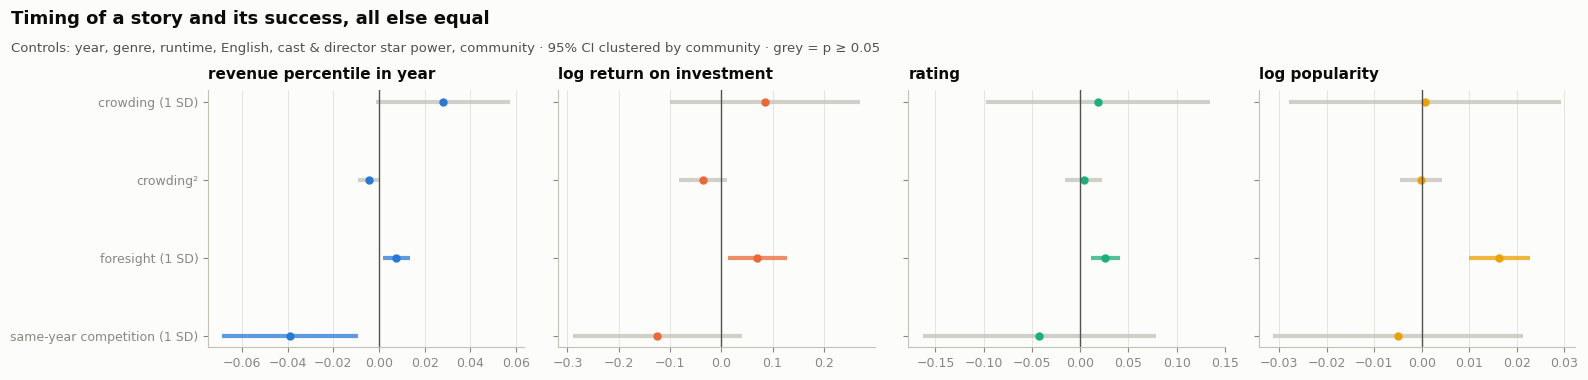

  ✓ figures/narrative_dynamics/fig_03_timing_coefficients.png + tables/narrative_dynamics/fig_03_timing_coefficients.csv


In [9]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 9 — Figure: timing coefficients across outcomes (T3)
# ═══════════════════════════════════════════════════════════════════════════
nice = {"crowding_z": "crowding (1 SD)", "I(crowding_z ** 2)": "crowding²", "foresight_z": "foresight (1 SD)",
        "competition_z": "same-year competition (1 SD)"}
t3 = timing[timing["model"] == "T3_plus_competition"]
terms = [t for t in nice if t in t3["term"].unique()]
fig, axes = plt.subplots(1, len(OUT), figsize=(4 * len(OUT), 0.5 * len(terms) + 1.8), sharey=True)
for ax, (y, name), color in zip(axes, OUT.items(), SERIES):
    t = t3[t3["outcome"] == y].set_index("term").reindex(terms)
    yy = np.arange(len(terms))[::-1]
    sig = t["p_value"] < 0.05
    ax.hlines(yy, t["ci_low"], t["ci_high"], color=np.where(sig, color, AXIS), linewidth=3, alpha=0.75)
    ax.plot(t["coef"], yy, "o", color=color, markersize=5)
    ax.axvline(0, color=INK_2, linewidth=1)
    ax.set_title(name, fontsize=11, pad=8)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(np.arange(len(terms))[::-1], [nice[t] for t in terms])
fig_header(fig, "Timing of a story and its success, all else equal",
           "Controls: year, genre, runtime, English, cast & director star power, community · 95% CI clustered by community · grey = p ≥ 0.05")
save(fig, t3, "fig_03_timing_coefficients")


## 4. Similar stories, similar fates?

**Network autocorrelation.** Moran's *I* asks whether films joined by a plot-similarity edge have more similar outcomes than random pairs. The outcome is first adjusted for release year and genre, so the test is about plot, not about genre or era. Significance comes from 499 random reshuffles of the outcomes over the same network.

,outcome,films,edges_used,morans_I,null_mean,null_p95,p_value
0,revenue_percentile_year,7547,12003,0.1209,-0.0002,0.0153,0.002
1,log_roi,4910,5820,0.0818,-0.0002,0.0213,0.002
2,vote_average,19084,70252,0.0983,-0.0001,0.0060,0.002
3,log_popularity,19084,70252,0.0529,-0.0000,0.0061,0.002


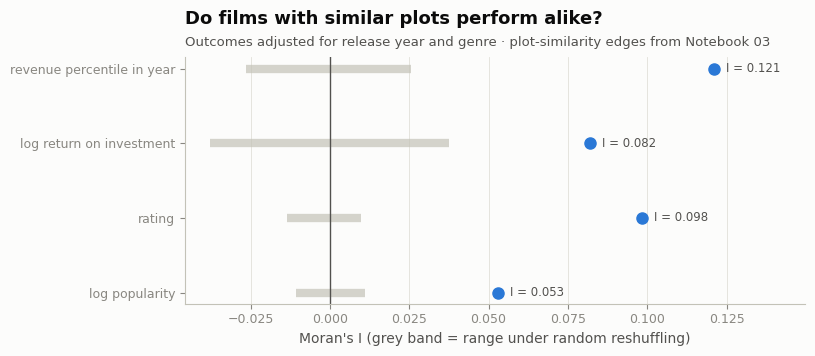

  ✓ figures/narrative_dynamics/fig_04_morans_i.png + tables/narrative_dynamics/fig_04_morans_i.csv


In [10]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 10 — Moran's I on the plot network (outcomes adjusted for year and genre)
# ═══════════════════════════════════════════════════════════════════════════
rng = np.random.default_rng(CFG["random_state"])
pos = pd.Series(np.arange(len(df)), index=df["node_id"])
a = edges["source_node_id"].map(pos).values
b = edges["target_node_id"].map(pos).values
keep_e = ~(np.isnan(a) | np.isnan(b))
a, b = a[keep_e].astype(int), b[keep_e].astype(int)

moran_rows, null_store = [], {}
for y in OUT:
    d = df.dropna(subset=[y])
    resid = pd.Series(np.nan, index=df.index)
    resid.loc[d.index] = smf.ols(f"{y} ~ C(release_year) + C(primary_genre_model)", d).fit().resid
    zz = (resid - resid.mean()) / resid.std()
    v = zz.values
    m_ = ~(np.isnan(v[a]) | np.isnan(v[b]))
    ea, eb = a[m_], b[m_]
    vv = np.where(np.isnan(v), 0.0, v)
    present = ~np.isnan(v)
    n_ = present.sum()
    def I(vals):
        return (n_ / len(ea)) * np.sum(vals[ea] * vals[eb]) / np.sum(vals[present] ** 2)
    obs = I(vv)
    idx = np.where(present)[0]
    null = np.empty(CFG["moran_permutations"])
    for i in range(len(null)):
        p_ = vv.copy(); p_[idx] = vv[rng.permutation(idx)]
        null[i] = I(p_)
    null_store[y] = null
    moran_rows.append({"outcome": y, "films": int(n_), "edges_used": int(len(ea)), "morans_I": obs,
                       "null_mean": null.mean(), "null_p95": np.quantile(null, 0.95),
                       "p_value": (np.sum(null >= obs) + 1) / (len(null) + 1)})
moran = pd.DataFrame(moran_rows)
display(moran.round(4))

fig, ax = plt.subplots(figsize=(8, 3.2))
yy = np.arange(len(moran))[::-1]
for i, r in zip(yy, moran.itertuples()):
    nl = null_store[r.outcome]
    ax.hlines(i, nl.min(), nl.max(), color=AXIS, linewidth=6, alpha=0.7)
    ax.plot(r.morans_I, i, "o", color=SERIES[0], markersize=8)
    ax.annotate(f"I = {r.morans_I:.3f}", (r.morans_I, i), xytext=(9, 0), textcoords="offset points",
                va="center", fontsize=8.5, color=INK_2)
ax.set_yticks(yy, [OUT[o] for o in moran["outcome"]])
ax.axvline(0, color=INK_2, linewidth=1)
ax.set_xlabel("Moran's I (grey band = range under random reshuffling)")
ax.set_xlim(right=ax.get_xlim()[1] + 0.12 * (ax.get_xlim()[1] - ax.get_xlim()[0]))
ax.grid(axis="y", visible=False)
ax.set_title("Do films with similar plots perform alike?")
subtitle(ax, "Outcomes adjusted for release year and genre · plot-similarity edges from Notebook 03")
save(fig, moran, "fig_04_morans_i")


**Out-of-sample prediction.** For every film, a *plot prior* is built from the outcomes of its 20 most similar films released in **earlier** years (similarity-weighted), and a *genre prior* from earlier films of the same genre — both are things a producer could have known before release. A further model uses the full 384-number plot embedding (ridge regression). Each is scored by cross-validated R² on films held out of training, on top of the Notebook 05 baseline (year, genre, runtime, English, star power).

revenue_percentile_year   done (n=6,939)
log_roi                   done (n=4,489)
vote_average              done (n=17,923)
log_popularity            done (n=17,923)


,outcome,features,n_films,cv_r2_mean,cv_r2_sd,forward_r2,forward_n_test,gain_over_baseline,forward_gain_over_baseline
0,revenue_percentile_year,baseline,6939,0.2882,0.0192,0.2117,2644,0.0000,0.0000
1,revenue_percentile_year,+ genre prior,6939,0.2880,0.0193,0.2024,2644,-0.0002,-0.0093
2,revenue_percentile_year,+ plot prior,6939,0.3061,0.0150,0.2358,2644,0.0179,0.0242
3,revenue_percentile_year,+ genre and plot prior,6939,0.3061,0.0150,0.2256,2644,0.0179,0.0139
4,revenue_percentile_year,+ full plot embedding (ridge),6939,0.3306,0.0172,0.2373,2644,0.0424,0.0256
5,log_roi,baseline,4489,0.0561,0.0122,0.0264,1398,0.0000,0.0000
6,log_roi,+ genre prior,4489,0.0565,0.0119,0.0186,1398,0.0004,-0.0078
7,log_roi,+ plot prior,4489,0.0635,0.0156,0.0387,1398,0.0074,0.0123
8,log_roi,+ genre and plot prior,4489,0.0639,0.0153,0.0315,1398,0.0078,0.0051
9,log_roi,+ full plot embedding (ridge),4489,0.0813,0.0135,0.0418,1398,0.0252,0.0154


  ✓ tables/narrative_dynamics/out_of_sample_prediction.csv


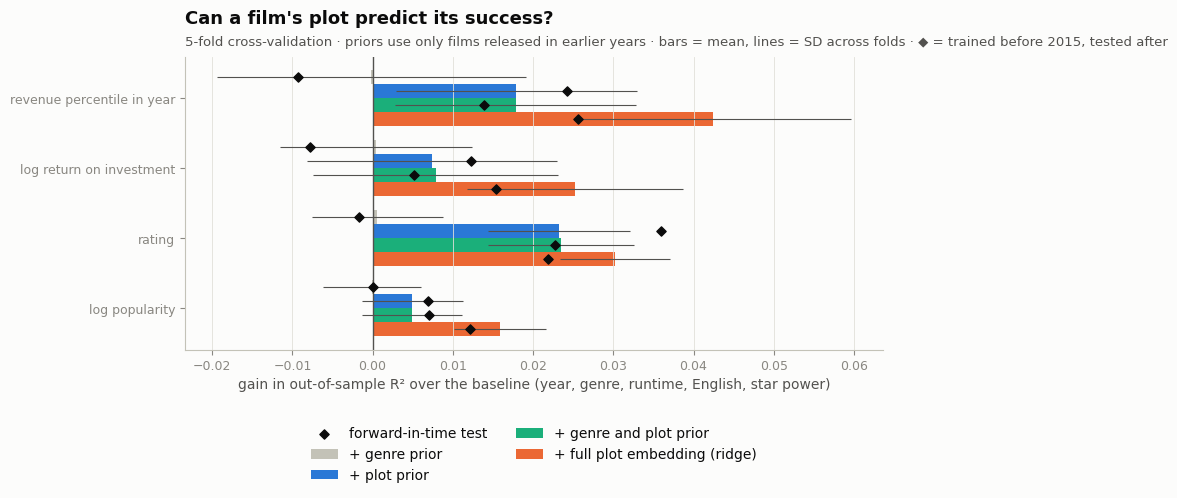

  ✓ figures/narrative_dynamics/fig_05_prediction_gain.png + tables/narrative_dynamics/fig_05_prediction_gain.csv


In [11]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 11 — Plot prior vs genre prior vs full embedding, cross-validated
# ═══════════════════════════════════════════════════════════════════════════
row_of = pd.Series(emb_index["row"].values, index=emb_index["tmdb_id"].values)
row_of = row_of[~row_of.index.duplicated()]

def plot_prior(d, y, k):
    """Similarity-weighted mean outcome of the k most similar films released in EARLIER years (no look-ahead)."""
    rows = d["tmdb_id"].map(row_of).values.astype(int)
    yrs, vals = d["release_year"].values, d[y].values
    out = np.full(len(d), np.nan)
    for yr in np.unique(yrs):
        q, pool = np.where(yrs == yr)[0], np.where(yrs < yr)[0]
        if len(pool) < k:
            continue
        S = E[rows[q]] @ E[rows[pool]].T
        top = np.argpartition(S, -k, axis=1)[:, -k:]
        w = np.clip(np.take_along_axis(S, top, axis=1), 0, None)
        out[q] = (w * vals[pool][top]).sum(1) / np.maximum(w.sum(1), 1e-9)
    return out

def genre_prior(d, y):
    """Mean outcome of earlier-year films of the same primary genre."""
    g = d.groupby(["primary_genre_model", "release_year"])[y].agg(["sum", "count"]).sort_index()
    cs = g.groupby(level=0).cumsum() - g                       # strictly earlier years
    prior = (cs["sum"] / cs["count"].replace(0, np.nan)).rename("genre_prior")
    return d.join(prior, on=["primary_genre_model", "release_year"])["genre_prior"].values

base_cols = ["z_runtime", "is_english", "z_star_index", "z_director_index", "has_star"]
cv_rows = []
kf = KFold(CFG["cv_folds"], shuffle=True, random_state=CFG["random_state"])
for y in OUT:
    d = df.dropna(subset=[y] + base_cols + ["primary_genre_model", "release_year"]).copy()
    d = d.sort_values("release_year").reset_index(drop=True)
    d["plot_prior"] = plot_prior(d, y, CFG["prior_k"])            # pool = all earlier films, incl. 1990–94
    d["genre_prior"] = genre_prior(d, y)
    d = d[d["release_year"] >= CFG["first_year"] + CFG["window_years"]]        # every film has a past to learn from
    d = d.dropna(subset=["plot_prior", "genre_prior"]).reset_index(drop=True)
    Xb = pd.get_dummies(d[["primary_genre_model"]].astype(str).assign(yr=d["release_year"].astype(str)),
                        drop_first=True).astype(float)
    Xb[base_cols] = d[base_cols].astype(float).values
    sets = {"baseline": Xb, "+ genre prior": Xb.assign(gp=d["genre_prior"].values),
            "+ plot prior": Xb.assign(pp=d["plot_prior"].values),
            "+ genre and plot prior": Xb.assign(gp=d["genre_prior"].values, pp=d["plot_prior"].values)}
    rows_emb = d["tmdb_id"].map(row_of).values.astype(int)
    yv = d[y].values
    for name, X in list(sets.items()) + [("+ full plot embedding (ridge)", None)]:
        scores = []
        for tr, te in kf.split(d):
            if X is None:
                Xf = np.hstack([Xb.values, E[rows_emb]])
                mdl = RidgeCV(alphas=CFG["ridge_alphas"]).fit(Xf[tr], yv[tr])
                pred = mdl.predict(Xf[te])
            else:
                mdl = LinearRegression().fit(X.values[tr], yv[tr])
                pred = mdl.predict(X.values[te])
            scores.append(r2_score(yv[te], pred))
        # forward-in-time test: learn from films up to split year, predict later films (year enters linearly)
        tr_t = np.where(d["release_year"].values < CFG["temporal_split_year"])[0]
        te_t = np.where(d["release_year"].values >= CFG["temporal_split_year"])[0]
        Xt = Xb.drop(columns=[c for c in Xb if c.startswith("yr_")]).assign(year=d["release_year"].values - 2000)
        if X is None:
            Xt = np.hstack([Xt.values, E[rows_emb]])
            pred_t = RidgeCV(alphas=CFG["ridge_alphas"]).fit(Xt[tr_t], yv[tr_t]).predict(Xt[te_t])
        else:
            extra = X[[c for c in X if c in ("gp", "pp")]].values
            Xt = np.hstack([Xt.values, extra])
            pred_t = LinearRegression().fit(Xt[tr_t], yv[tr_t]).predict(Xt[te_t])
        cv_rows.append({"outcome": y, "features": name, "n_films": len(d), "cv_r2_mean": np.mean(scores),
                        "cv_r2_sd": np.std(scores), "forward_r2": r2_score(yv[te_t], pred_t),
                        "forward_n_test": len(te_t)})
    print(f"{y:25s} done (n={len(d):,})")
cv = pd.DataFrame(cv_rows)
cv["gain_over_baseline"] = cv["cv_r2_mean"] - cv.groupby("outcome")["cv_r2_mean"].transform("first")
cv["forward_gain_over_baseline"] = cv["forward_r2"] - cv.groupby("outcome")["forward_r2"].transform("first")
display(cv.round(4))
save_tab(cv.round(5), "out_of_sample_prediction.csv")

feat_order = cv["features"].unique().tolist()[1:]
fig, ax = plt.subplots(figsize=(9, 3.8))
width = 0.8 / len(feat_order)
for j, (f, color) in enumerate(zip(feat_order, [AXIS, SERIES[0], SERIES[2], SERIES[1]])):
    g = cv[cv["features"] == f].set_index("outcome").reindex(list(OUT))
    ax.barh(np.arange(len(OUT)) + j * width, g["gain_over_baseline"], height=width, color=color, label=f,
            xerr=g["cv_r2_sd"], error_kw={"elinewidth": 0.8, "ecolor": INK_2})
    ax.scatter(g["forward_gain_over_baseline"], np.arange(len(OUT)) + j * width, marker="D", s=22,
               color=INK, zorder=3, label="forward-in-time test" if j == 0 else None)
ax.set_yticks(np.arange(len(OUT)) + width * (len(feat_order) - 1) / 2, list(OUT.values()))
ax.invert_yaxis()
ax.axvline(0, color=INK_2, linewidth=1)
ax.set_xlabel("gain in out-of-sample R² over the baseline (year, genre, runtime, English, star power)")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)
ax.set_title("Can a film's plot predict its success?")
subtitle(ax, f"{CFG['cv_folds']}-fold cross-validation · priors use only films released in earlier years · bars = mean, lines = SD across folds · ◆ = trained before {CFG['temporal_split_year']}, tested after")
save(fig, cv, "fig_05_prediction_gain")


In [12]:
# ═══════════════════════════════════════════════════════════════════════════
# CELL 12 — Notes for the Results chapter (written from the numbers)
# ═══════════════════════════════════════════════════════════════════════════
def term(y, t, m="T3_plus_competition"):
    r = timing[(timing["outcome"] == y) & (timing["model"] == m) & (timing["term"] == t)]
    return None if r.empty else r.iloc[0]

lines = ["Narrative dynamics notes", ""]
sig = trend[trend["p_value"] < 0.05]
up = sig[sig["trend_pp_per_decade"] > 0].tail(3)
down = sig[sig["trend_pp_per_decade"] < 0].head(3)
if len(up):
    lines.append("Rising narratives (share per decade, significant): " + "; ".join(
        f"{r.label} ({r.trend_pp_per_decade:+.2f} pp)" for r in up[::-1].itertuples()) + ".")
if len(down):
    lines.append("Fading narratives (significant): " + "; ".join(f"{r.label} ({r.trend_pp_per_decade:+.2f} pp)" for r in down.itertuples()) + ".")
for y, name in OUT.items():
    parts = []
    for t, label in [("crowding_z", "crowding"), ("foresight_z", "foresight"), ("competition_z", "same-year competition")]:
        r = term(y, t)
        if r is not None:
            parts.append(f"{label} {r['coef']:+.3f} (p={r['p_value']:.2g})")
    r2g = timing[(timing["outcome"] == y) & (timing["model"] == "T3_plus_competition")]["r2_gain_over_base"]
    lines.append(f"{name}: " + ", ".join(parts) + (f"; R² gain over Notebook 05 controls {r2g.iloc[0]:.4f}." if len(r2g) else "."))
for r in moran.itertuples():
    lines.append(f"Moran's I for {OUT[r.outcome]} (adjusted for year and genre): {r.morans_I:.3f} "
                 f"(random-network 95th percentile {r.null_p95:.3f}, p={r.p_value:.3f}) — "
                 + ("films with similar plots have similar outcomes." if r.p_value < 0.05 else "no clustering of outcomes by plot."))
for y in OUT:
    g = cv[cv["outcome"] == y].set_index("features")
    best = g["gain_over_baseline"].drop("baseline").idxmax()
    lines.append(f"Out-of-sample {OUT[y]}: baseline R² {g.loc['baseline', 'cv_r2_mean']:.3f}; plot prior adds "
                 f"{g.loc['+ plot prior', 'gain_over_baseline']:+.4f}, genre prior {g.loc['+ genre prior', 'gain_over_baseline']:+.4f}, "
                 f"full embedding {g.loc['+ full plot embedding (ridge)', 'gain_over_baseline']:+.4f} (best: {best}). "
                 f"Forward-in-time test (train <{CFG['temporal_split_year']}, predict later films): plot prior "
                 f"{g.loc['+ plot prior', 'forward_gain_over_baseline']:+.4f}, genre prior "
                 f"{g.loc['+ genre prior', 'forward_gain_over_baseline']:+.4f}, full embedding "
                 f"{g.loc['+ full plot embedding (ridge)', 'forward_gain_over_baseline']:+.4f}.")
lines.append("Measures are standardised within release year; crowding uses films from the 5 previous years only, "
             "foresight compares the 5 following with the 5 previous years. All results are associations.")
notes = "\n".join(lines)
(D_TABLES / "narrative_dynamics_notes.txt").write_text(notes, encoding="utf-8")
print(notes)
print("\n  ✓ tables/narrative_dynamics/narrative_dynamics_notes.txt")


Narrative dynamics notes

Rising narratives (share per decade, significant): Family secrets, siblings and domestic threat (+1.04 pp); French relationship and family drama-comedy (+0.84 pp); Supernatural horror: hauntings, demons and possession (+0.68 pp).
Fading narratives (significant): Crime, policing and the criminal underworld (-2.06 pp); Romance, marriage and relationship drama-comedy (-0.49 pp); Espionage, secret agents, terrorism and hackers (-0.42 pp).
revenue percentile in year: crowding +0.028 (p=0.062), foresight +0.008 (p=0.012), same-year competition -0.039 (p=0.01); R² gain over Notebook 05 controls 0.0029.
log return on investment: crowding +0.086 (p=0.37), foresight +0.070 (p=0.018), same-year competition -0.125 (p=0.14); R² gain over Notebook 05 controls 0.0029.
rating: crowding +0.019 (p=0.75), foresight +0.026 (p=0.00081), same-year competition -0.042 (p=0.49); R² gain over Notebook 05 controls 0.0012.
log popularity: crowding +0.001 (p=0.97), foresight +0.016 (p=8.3

## How to use these results

* **Figure 1** (narrative trends) is descriptive and stands on its own: which stories rose and faded.
* **Figures 2–3** test whether *timing* matters: crowded niches vs stories ahead of their time.
* **Figures 4–5** answer the thesis question most directly: do similar plots share similar fates, and does knowing a film's plot neighbours improve predictions on unseen films beyond genre?
* `processed/features/time_aware_plot_features.csv` holds the per-film measures for the presentation bricks.